
# Phase 5 - Super-Clustering Contextual v5 (Improved)

Objetivo: mejorar la calidad contextual de embeddings y la seleccion de regimenes en GBPUSD.

Mejoras sobre v2/v4:
- Busqueda de hiperparametros del encoder (sin usar test).
- Fine-tuning con objetivo combinado MLM + consistencia contrastiva.
- Seleccion de K robusta en validacion (geometria + estabilidad + senal economica).
- Comparacion automatica contra v2 y v4 transfer.


DEVICE = cuda
OUT_DIR = ./phases/phase05_context_sequencing/output_superclustering_contextual_GBPUSD_v5_improved


EURUSD segments= 1748 windows= 1717


GBPUSD segments= 1636 windows= 1605
total windows = 3322 | target windows = 1605
target split counts = {'train': 1123, 'val': 241, 'test': 241}
vocab_size = 10 | num_symbols = 2

Training candidate: cfg_a


<python-env>/lib/python3.11/site-packages/torch/nn/modules/transformer.py:385: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  warnings.warn(


[cfg_a] early stopping at ep=10


...

,candidate,seed,d_model,n_layers,dropout,emb_dim,best_val_loss,best_k_val,val_eta2_bestk,val_kw_p_bestk,robust_score_bestk,selection_score
0,cfg_c,62,96,3,0.20,72,2.397512,10,0.027938,0.185003,3.370562,0.095350
1,cfg_b,52,128,4,0.15,80,2.563495,4,0.006273,0.504398,3.154283,0.069358
2,cfg_a,42,96,3,0.12,64,2.157507,4,0.018759,0.182266,1.464766,0.048054


<python-env>/lib/python3.11/site-packages/torch/nn/modules/transformer.py:385: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  warnings.warn(


saved summary = ./phases/phase05_context_sequencing/output_superclustering_contextual_GBPUSD_v5_improved/GBPUSD_superclustering_summary_v5.json
BEST_K = 10 | kw_p = 0.02300200780850246 | eta2 = 0.060452414575569685


,regime_id,n,mean_ret,median_ret,std_ret,t_like
0,7,59,-45.774609,-62.199831,136.835267,-0.334523
1,4,56,6.112435,10.449886,104.445099,0.058523
2,8,44,9.588653,7.649660,93.417159,0.102643
3,5,30,-21.049817,-9.799004,76.511593,-0.275119
4,1,20,43.124914,30.650496,136.523394,0.315879
5,2,16,21.581203,16.350150,168.917783,0.127762
6,0,10,-15.779972,8.599758,108.851021,-0.144969
7,3,6,-7.766684,-3.150105,46.152904,-0.168282


,metric,v2,v4,v5
0,best_k,6.000000,4.000000,10.000000
1,kw_pvalue_test,0.004396,0.156393,0.023002
2,anova_pvalue_test,0.004857,0.070865,0.012388
3,eta2_test,0.063914,0.022853,0.060452


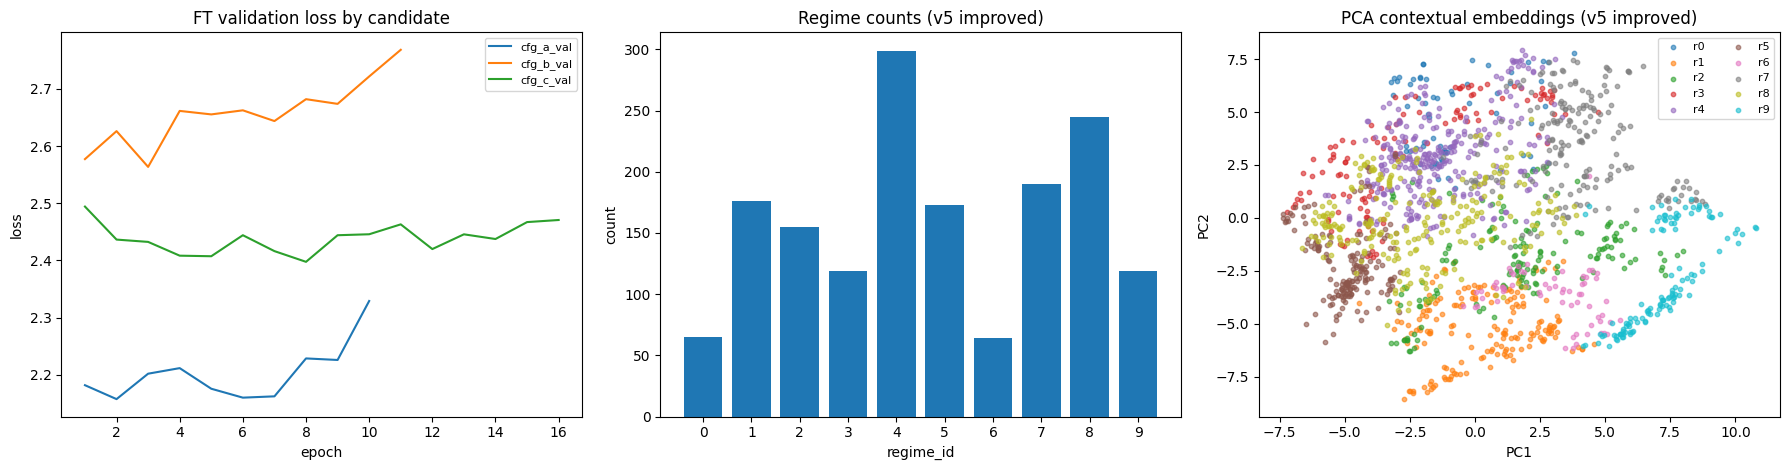

In [1]:

import json
import math
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, calinski_harabasz_score, davies_bouldin_score, adjusted_rand_score
from scipy.stats import kruskal, f_oneway

pd.set_option('display.max_columns', 320)
pd.set_option('display.width', 360)

# =========================
# Config
# =========================
TARGET_SYMBOL = 'GBPUSD'
SOURCE_SYMBOLS = ['EURUSD']
ALL_SYMBOLS = SOURCE_SYMBOLS + [TARGET_SYMBOL]
SEQ_LEN = 32
SEED = 42
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'

TRAIN_RATIO = 0.70
VAL_RATIO = 0.15
TEST_RATIO = 0.15
assert abs(TRAIN_RATIO + VAL_RATIO + TEST_RATIO - 1.0) < 1e-9

DELTA_BINS = 24
SIGN_BINS = 3
BATCH_SIZE = 64
WEIGHT_DECAY = 1e-4
N_INIT_KMEANS = 40
K_CANDIDATES = list(range(4, 13))
KMEANS_SEEDS = [11, 42, 77]
HORIZON_HOURS = 24
MIN_CLUSTER_N = 20

# busqueda de hiperparametros (todo se selecciona con validacion)
CANDIDATES = [
    {
        'tag': 'cfg_a',
        'd_model': 96, 'n_head': 4, 'n_layers': 3, 'ff_dim': 192, 'dropout': 0.12,
        'emb_dim': 64, 'mask_pre': 0.18, 'mask_ft': 0.15,
        'epochs_pre': 20, 'epochs_ft': 24,
        'lr_pre': 8e-4, 'lr_ft': 4e-4,
        'patience_ft': 7, 'label_smooth': 0.02,
        'lambda_contrast': 0.15,
        'seed': 42,
    },
    {
        'tag': 'cfg_b',
        'd_model': 128, 'n_head': 8, 'n_layers': 4, 'ff_dim': 256, 'dropout': 0.15,
        'emb_dim': 80, 'mask_pre': 0.20, 'mask_ft': 0.16,
        'epochs_pre': 22, 'epochs_ft': 28,
        'lr_pre': 7e-4, 'lr_ft': 3e-4,
        'patience_ft': 8, 'label_smooth': 0.03,
        'lambda_contrast': 0.20,
        'seed': 52,
    },
    {
        'tag': 'cfg_c',
        'd_model': 96, 'n_head': 4, 'n_layers': 3, 'ff_dim': 224, 'dropout': 0.20,
        'emb_dim': 72, 'mask_pre': 0.22, 'mask_ft': 0.18,
        'epochs_pre': 18, 'epochs_ft': 30,
        'lr_pre': 9e-4, 'lr_ft': 3.5e-4,
        'patience_ft': 8, 'label_smooth': 0.03,
        'lambda_contrast': 0.25,
        'seed': 62,
    },
]

PHASE4_ROOT = Path('./phases/phase04_transfer_clustering')
PRICE_DIR = Path('./data/Dataset_H1_v1/parquet_h1')
PREV_V2_SUMMARY = Path('./phases/phase05_context_sequencing/output_superclustering_contextual_GBPUSD_v2/GBPUSD_superclustering_summary.json')
PREV_V4_SUMMARY = Path('./phases/phase05_context_sequencing/output_superclustering_contextual_GBPUSD_v4_transfer/GBPUSD_superclustering_summary_v4.json')

OUT_DIR = Path('./phases/phase05_context_sequencing/output_superclustering_contextual_GBPUSD_v5_improved')
OUT_DIR.mkdir(parents=True, exist_ok=True)

HISTORY_CSV = OUT_DIR / 'GBPUSD_train_history_v5.csv'
HP_SEARCH_CSV = OUT_DIR / 'GBPUSD_hparam_search_v5.csv'
ENCODER_PT = OUT_DIR / 'GBPUSD_context_encoder_v5.pt'
WINDOWS_PQ = OUT_DIR / 'multi_fx_windows_len32_v5.parquet'
MODEL_SELECTION_CSV = OUT_DIR / 'GBPUSD_superclustering_model_selection_v5.csv'
EMB_PQ = OUT_DIR / 'GBPUSD_context_window_embeddings_v5.parquet'
EMB_CSV = OUT_DIR / 'GBPUSD_context_window_embeddings_v5.csv'
PROFILE_CSV = OUT_DIR / 'GBPUSD_context_regime_profile_v5.csv'
TRANS_CSV = OUT_DIR / 'GBPUSD_context_regime_transition_matrix_v5.csv'
SUMMARY_JSON = OUT_DIR / 'GBPUSD_superclustering_summary_v5.json'

print('DEVICE =', DEVICE)
print('OUT_DIR =', OUT_DIR)

# =========================
# Helpers
# =========================
def set_seed(seed: int):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed(SEED)


def pip_size(symbol: str) -> float:
    return 0.01 if str(symbol).upper().endswith('JPY') else 0.0001


def temporal_split(n: int, train_ratio: float, val_ratio: float):
    tr_end = int(n * train_ratio)
    va_end = int(n * (train_ratio + val_ratio))
    tr_end = max(1, min(tr_end, n - 2))
    va_end = max(tr_end + 1, min(va_end, n - 1))
    idx_train = np.arange(0, tr_end)
    idx_val = np.arange(tr_end, va_end)
    idx_test = np.arange(va_end, n)
    return idx_train, idx_val, idx_test


def zscore_col(x: pd.Series, eps: float = 1e-9):
    m = float(x.mean())
    s = float(x.std(ddof=0))
    if not np.isfinite(s) or s < eps:
        return pd.Series(np.zeros(len(x)), index=x.index, dtype=float)
    return (x - m) / (s + eps)


def load_assignments(symbol: str) -> pd.DataFrame:
    p = PHASE4_ROOT / f'output_transfer_{symbol}_full_v2' / f'{symbol}_segment_cluster_assignments.parquet'
    if not p.exists():
        raise FileNotFoundError(f'Missing assignments for {symbol}: {p}')
    d = pd.read_parquet(p).copy()
    d['start_ts'] = pd.to_datetime(d['start_ts'], errors='coerce')
    d['end_ts'] = pd.to_datetime(d['end_ts'], errors='coerce')
    d = d.sort_values(['start_ts', 'global_segment_id']).reset_index(drop=True)
    d['symbol'] = symbol
    return d


def build_stream(df: pd.DataFrame) -> pd.DataFrame:
    d = df.copy().sort_values(['start_ts', 'global_segment_id']).reset_index(drop=True)
    d['cluster_id'] = d['cluster_id'].astype(int)
    d['token'] = d['cluster_id'].map(lambda x: f'c{x:02d}')
    d['event_idx'] = np.arange(len(d), dtype=int)
    d['delta_prev_h'] = ((d['start_ts'] - d['start_ts'].shift(1)) / np.timedelta64(1, 'h')).fillna(0.0).astype(float)
    d['move_sign'] = np.sign(pd.to_numeric(d['move_pips'], errors='coerce').fillna(0.0)).astype(int)
    return d


def build_windows(stream_df: pd.DataFrame, seq_len: int = 32, stride: int = 1) -> pd.DataFrame:
    d = stream_df.sort_values('start_ts').reset_index(drop=True)
    rows = []
    if len(d) < seq_len:
        return pd.DataFrame(columns=['window_id','symbol','start_ts','end_ts','token_seq','delta_h_seq','move_sign_seq'])
    for i in range(0, len(d) - seq_len + 1, stride):
        w = d.iloc[i:i+seq_len]
        rows.append({
            'window_id': int(i),
            'symbol': str(w['symbol'].iloc[0]),
            'start_ts': pd.Timestamp(w['start_ts'].iloc[0]),
            'end_ts': pd.Timestamp(w['start_ts'].iloc[-1]),
            'token_seq': w['token'].astype(str).tolist(),
            'delta_h_seq': pd.to_numeric(w['delta_prev_h'], errors='coerce').fillna(0.0).astype(float).tolist(),
            'move_sign_seq': pd.to_numeric(w['move_sign'], errors='coerce').fillna(0).astype(int).tolist(),
        })
    return pd.DataFrame(rows)


def delta_to_bins(delta_arr: np.ndarray, delta_max: float, n_bins: int):
    x = np.asarray(delta_arr, dtype=float)
    x = np.clip(x, 0.0, max(1e-6, float(delta_max)))
    z = np.log1p(x) / np.log1p(max(1e-6, float(delta_max)))
    b = np.floor(z * (n_bins - 1 + 1e-12)).astype(int)
    return np.clip(b, 0, n_bins - 1)


def compute_forward_pips(df_price: pd.DataFrame, ts_vec: pd.Series, symbol: str, horizon_hours: int = 24):
    idx = df_price['timestamp'].to_numpy(dtype='datetime64[ns]')
    close = df_price['close'].to_numpy(dtype=float)
    ts = pd.to_datetime(ts_vec, errors='coerce').to_numpy(dtype='datetime64[ns]')
    pos = np.searchsorted(idx, ts, side='left')
    out = np.full(len(ts), np.nan, dtype=float)
    ps = pip_size(symbol)
    for i in range(len(ts)):
        p0 = pos[i]
        p1 = p0 + int(horizon_hours)
        if p0 < 0 or p1 >= len(idx):
            continue
        if idx[p0] != ts[i]:
            continue
        out[i] = (close[p1] - close[p0]) / ps
    return out


def make_masked_inputs(x: torch.Tensor, vocab_size: int, mask_id: int, mask_prob: float = 0.15):
    labels = x.clone()
    prob = torch.rand_like(x.float())
    masked = prob < mask_prob
    labels[~masked] = -100
    x_in = x.clone()
    if masked.any():
        r = torch.rand_like(x.float())
        mask_pos = masked & (r < 0.8)
        rand_pos = masked & (r >= 0.8) & (r < 0.9)
        x_in[mask_pos] = mask_id
        if rand_pos.any():
            rnd = torch.randint(low=0, high=vocab_size, size=(rand_pos.sum().item(),), device=x.device)
            x_in[rand_pos] = rnd
    return x_in, labels


def contrastive_ntxent(z1: torch.Tensor, z2: torch.Tensor, temperature: float = 0.2) -> torch.Tensor:
    z1 = F.normalize(z1, dim=1)
    z2 = F.normalize(z2, dim=1)
    logits = z1 @ z2.T / temperature
    labels = torch.arange(z1.size(0), device=z1.device)
    return 0.5 * (F.cross_entropy(logits, labels) + F.cross_entropy(logits.T, labels))


# =========================
# Build windows
# =========================
all_win = []
for sym in ALL_SYMBOLS:
    a = load_assignments(sym)
    s = build_stream(a)
    w = build_windows(s, seq_len=SEQ_LEN, stride=1)
    w['symbol'] = sym
    all_win.append(w)
    print(sym, 'segments=', len(s), 'windows=', len(w))

W_ALL = pd.concat(all_win, ignore_index=True)
W_ALL = W_ALL.sort_values(['symbol', 'start_ts', 'window_id']).reset_index(drop=True)

W_T = W_ALL[W_ALL['symbol'] == TARGET_SYMBOL].copy().sort_values('start_ts').reset_index(drop=True)
idx_tr_t, idx_va_t, idx_te_t = temporal_split(len(W_T), TRAIN_RATIO, VAL_RATIO)
spl_t = np.array(['train'] * len(W_T), dtype=object)
spl_t[idx_va_t] = 'val'
spl_t[idx_te_t] = 'test'
W_T['split'] = spl_t

W_S = W_ALL[W_ALL['symbol'].isin(SOURCE_SYMBOLS)].copy().sort_values(['symbol', 'start_ts']).reset_index(drop=True)
W_S['split'] = 'pretrain_source'

W = pd.concat([W_S, W_T], ignore_index=True)
W = W.sort_values(['symbol', 'start_ts']).reset_index(drop=True)
W.to_parquet(WINDOWS_PQ, index=False)

# vocab + arrays
tokens = sorted({str(t) for row in W['token_seq'] for t in row})
token_to_id = {t: i for i, t in enumerate(tokens)}
vocab_size = len(token_to_id)
mask_id = vocab_size
cls_id = vocab_size + 1

symbol_to_id = {s: i for i, s in enumerate(sorted(W['symbol'].unique().tolist()))}
num_symbols = len(symbol_to_id)

tok = np.vstack([np.array([token_to_id[str(t)] for t in row], dtype=np.int64) for row in W['token_seq']])
dlt = np.vstack([np.asarray(row, dtype=float) for row in W['delta_h_seq']])
sgn = np.vstack([np.asarray(row, dtype=int) for row in W['move_sign_seq']])
sgn = np.clip(sgn + 1, 0, 2).astype(np.int64)
sym = W['symbol'].map(symbol_to_id).to_numpy(dtype=np.int64)

target_mask = W['symbol'] == TARGET_SYMBOL
W_target_idx = np.where(target_mask.to_numpy())[0]
idx_target_train = W_target_idx[np.where(W.loc[target_mask, 'split'].to_numpy() == 'train')[0]]
idx_target_val = W_target_idx[np.where(W.loc[target_mask, 'split'].to_numpy() == 'val')[0]]
idx_target_test = W_target_idx[np.where(W.loc[target_mask, 'split'].to_numpy() == 'test')[0]]

# calibrate bins with target train only
delta_max = float(np.nanquantile(dlt[idx_target_train].reshape(-1), 0.99))
delta_max = max(1.0, delta_max)
dlt_bin = delta_to_bins(dlt, delta_max=delta_max, n_bins=DELTA_BINS).astype(np.int64)

idx_pretrain = np.where((W['split'] == 'pretrain_source') | ((W['symbol'] == TARGET_SYMBOL) & (W['split'] == 'train')))[0]
idx_target_all = np.where(W['symbol'].to_numpy() == TARGET_SYMBOL)[0]

print('total windows =', len(W), '| target windows =', len(idx_target_all))
print('target split counts =', W_T['split'].value_counts().to_dict())
print('vocab_size =', vocab_size, '| num_symbols =', num_symbols)


# =========================
# Dataset + model
# =========================
class SeqDataset(Dataset):
    def __init__(self, tok_arr, dlt_arr, sgn_arr, sym_arr, indices):
        idx = np.asarray(indices, dtype=int)
        self.tok = torch.from_numpy(tok_arr[idx]).long()
        self.dlt = torch.from_numpy(dlt_arr[idx]).long()
        self.sgn = torch.from_numpy(sgn_arr[idx]).long()
        self.sym = torch.from_numpy(sym_arr[idx]).long()

    def __len__(self):
        return len(self.tok)

    def __getitem__(self, i):
        return self.tok[i], self.dlt[i], self.sgn[i], self.sym[i]


class ContextTransformer(nn.Module):
    def __init__(self, vocab_size, mask_id, cls_id, seq_len, d_model, n_head, n_layers, ff_dim, dropout, delta_bins, sign_bins, emb_dim, num_symbols):
        super().__init__()
        self.vocab_size = int(vocab_size)
        self.mask_id = int(mask_id)
        self.cls_id = int(cls_id)

        self.token_emb = nn.Embedding(vocab_size + 2, d_model)
        self.delta_emb = nn.Embedding(delta_bins, d_model)
        self.sign_emb = nn.Embedding(sign_bins, d_model)
        self.sym_emb = nn.Embedding(num_symbols, d_model)
        self.pos_emb = nn.Parameter(torch.randn(1, seq_len + 1, d_model) * 0.02)

        enc_layer = nn.TransformerEncoderLayer(
            d_model=d_model,
            nhead=n_head,
            dim_feedforward=ff_dim,
            dropout=dropout,
            activation='gelu',
            batch_first=True,
            norm_first=True,
        )
        self.encoder = nn.TransformerEncoder(enc_layer, num_layers=n_layers)
        self.norm = nn.LayerNorm(d_model)
        self.to_emb = nn.Sequential(
            nn.Linear(d_model, d_model),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(d_model, emb_dim),
        )
        self.mlm_head = nn.Linear(d_model, vocab_size)

    def forward(self, tok_ids, dlt_ids, sgn_ids, sym_ids):
        B = tok_ids.shape[0]
        cls_tok = torch.full((B, 1), self.cls_id, device=tok_ids.device, dtype=torch.long)
        cls_dlt = torch.zeros((B, 1), device=dlt_ids.device, dtype=torch.long)
        cls_sgn = torch.ones((B, 1), device=sgn_ids.device, dtype=torch.long)

        t = torch.cat([cls_tok, tok_ids], dim=1)
        d = torch.cat([cls_dlt, dlt_ids], dim=1)
        s = torch.cat([cls_sgn, sgn_ids], dim=1)

        sym_vec = self.sym_emb(sym_ids).unsqueeze(1)
        h = self.token_emb(t) + self.delta_emb(d) + self.sign_emb(s) + sym_vec
        h = h + self.pos_emb[:, :h.shape[1], :]
        h = self.encoder(h)
        h = self.norm(h)

        cls_h = h[:, 0, :]
        z = self.to_emb(cls_h)
        logits = self.mlm_head(h[:, 1:, :])
        return logits, z

    def encode(self, tok_ids, dlt_ids, sgn_ids, sym_ids):
        _, z = self.forward(tok_ids, dlt_ids, sgn_ids, sym_ids)
        return z


def encode_indices(model, indices, bs=256):
    model.eval()
    out = []
    with torch.no_grad():
        for i in range(0, len(indices), bs):
            idx = indices[i:i+bs]
            xb_tok = torch.from_numpy(tok[idx]).long().to(DEVICE)
            xb_dlt = torch.from_numpy(dlt_bin[idx]).long().to(DEVICE)
            xb_sgn = torch.from_numpy(sgn[idx]).long().to(DEVICE)
            xb_sym = torch.from_numpy(sym[idx]).long().to(DEVICE)
            z = model.encode(xb_tok, xb_dlt, xb_sgn, xb_sym)
            out.append(z.detach().cpu().numpy())
    return np.vstack(out).astype(np.float32)


def select_k_on_val(Z_t, idx_tr, idx_va, ret_val):
    sc = StandardScaler()
    Ztr = sc.fit_transform(Z_t[idx_tr])
    Zva = sc.transform(Z_t[idx_va])

    rows = []
    for k in K_CANDIDATES:
        seed_labels = {}
        sils, chs, dbs = [], [], []

        for sd in KMEANS_SEEDS:
            km = KMeans(n_clusters=k, n_init=N_INIT_KMEANS, random_state=sd)
            km.fit(Ztr)
            lv = km.predict(Zva)
            seed_labels[sd] = lv
            if len(np.unique(lv)) >= 2 and len(lv) > k:
                sils.append(float(silhouette_score(Zva, lv)))
                chs.append(float(calinski_harabasz_score(Zva, lv)))
                dbs.append(float(davies_bouldin_score(Zva, lv)))

        aris = []
        seeds = list(seed_labels.keys())
        for i in range(len(seeds)):
            for j in range(i+1, len(seeds)):
                aris.append(float(adjusted_rand_score(seed_labels[seeds[i]], seed_labels[seeds[j]])))

        lv = seed_labels[42]
        ok = np.isfinite(ret_val)
        groups = []
        for cid in np.unique(lv[ok]):
            x = ret_val[ok][lv[ok] == cid]
            if len(x) >= MIN_CLUSTER_N:
                groups.append(x)

        val_kw = np.nan
        val_eta2 = np.nan
        if len(groups) >= 2:
            val_kw = float(kruskal(*groups).pvalue)
            all_vals = np.concatenate(groups)
            gm = np.mean(all_vals)
            ssb = sum(len(g) * (np.mean(g) - gm) ** 2 for g in groups)
            sst = np.sum((all_vals - gm) ** 2)
            val_eta2 = float(ssb / sst) if sst > 0 else np.nan

        rows.append({
            'k': int(k),
            'sil_val_mean': float(np.mean(sils)) if len(sils) else np.nan,
            'ch_val_mean': float(np.mean(chs)) if len(chs) else np.nan,
            'db_val_mean': float(np.mean(dbs)) if len(dbs) else np.nan,
            'stability_ari_mean': float(np.mean(aris)) if len(aris) else np.nan,
            'val_kw_p': val_kw,
            'val_eta2': val_eta2,
        })

    SEL = pd.DataFrame(rows)
    SEL['z_sil'] = zscore_col(SEL['sil_val_mean'])
    SEL['z_ch'] = zscore_col(SEL['ch_val_mean'])
    SEL['z_db'] = zscore_col(SEL['db_val_mean'])
    SEL['z_ari'] = zscore_col(SEL['stability_ari_mean'])
    SEL['z_val_eta2'] = zscore_col(SEL['val_eta2'].fillna(0.0))
    SEL['robust_score'] = SEL['z_sil'] + 0.8 * SEL['z_ch'] - 0.8 * SEL['z_db'] + 0.6 * SEL['z_ari'] + 1.0 * SEL['z_val_eta2']
    SEL = SEL.sort_values('robust_score', ascending=False, na_position='last').reset_index(drop=True)
    best_k = int(SEL.iloc[0]['k'])
    return sc, SEL, best_k


# ===== data loaders fijos =====
pin = DEVICE == 'cuda'
pre_loader = DataLoader(SeqDataset(tok, dlt_bin, sgn, sym, idx_pretrain), batch_size=BATCH_SIZE, shuffle=True, pin_memory=pin)
ft_train_loader = DataLoader(SeqDataset(tok, dlt_bin, sgn, sym, idx_target_train), batch_size=BATCH_SIZE, shuffle=True, pin_memory=pin)
ft_val_loader = DataLoader(SeqDataset(tok, dlt_bin, sgn, sym, idx_target_val), batch_size=BATCH_SIZE, shuffle=False, pin_memory=pin)

# retorno forward para validacion economica
PX = pd.read_parquet(PRICE_DIR / f'{TARGET_SYMBOL}.parquet', columns=['timestamp','close']).copy()
PX['timestamp'] = pd.to_datetime(PX['timestamp'], errors='coerce')
PX['close'] = pd.to_numeric(PX['close'], errors='coerce')
PX = PX.dropna().sort_values('timestamp').drop_duplicates('timestamp', keep='last').reset_index(drop=True)

W_target_all = W.iloc[idx_target_all].copy().reset_index(drop=True)
idx_tr = np.where(W_target_all['split'].to_numpy() == 'train')[0]
idx_va = np.where(W_target_all['split'].to_numpy() == 'val')[0]
idx_te = np.where(W_target_all['split'].to_numpy() == 'test')[0]
ret_val = compute_forward_pips(PX, W_target_all.iloc[idx_va]['end_ts'], symbol=TARGET_SYMBOL, horizon_hours=HORIZON_HOURS)

# =========================
# Hparam search
# =========================
hist_rows = []
search_rows = []
best = {
    'score': -np.inf,
    'cfg': None,
    'state_dict': None,
    'best_k': None,
    'sel': None,
    'scaler': None,
    'Z_t': None,
    'best_val_loss': np.inf,
}

for cfg in CANDIDATES:
    set_seed(int(cfg['seed']))
    print('\n' + '=' * 90)
    print('Training candidate:', cfg['tag'])

    model = ContextTransformer(
        vocab_size=vocab_size,
        mask_id=mask_id,
        cls_id=cls_id,
        seq_len=SEQ_LEN,
        d_model=cfg['d_model'],
        n_head=cfg['n_head'],
        n_layers=cfg['n_layers'],
        ff_dim=cfg['ff_dim'],
        dropout=cfg['dropout'],
        delta_bins=DELTA_BINS,
        sign_bins=SIGN_BINS,
        emb_dim=cfg['emb_dim'],
        num_symbols=num_symbols,
    ).to(DEVICE)

    criterion = nn.CrossEntropyLoss(ignore_index=-100, label_smoothing=float(cfg['label_smooth']))

    # ---- pretrain MLM ----
    opt_pre = torch.optim.AdamW(model.parameters(), lr=float(cfg['lr_pre']), weight_decay=WEIGHT_DECAY)
    sch_pre = torch.optim.lr_scheduler.CosineAnnealingLR(opt_pre, T_max=int(cfg['epochs_pre']), eta_min=float(cfg['lr_pre']) * 0.1)

    for ep in range(1, int(cfg['epochs_pre']) + 1):
        model.train()
        losses = []
        for xb_tok, xb_dlt, xb_sgn, xb_sym in pre_loader:
            xb_tok = xb_tok.to(DEVICE, non_blocking=True)
            xb_dlt = xb_dlt.to(DEVICE, non_blocking=True)
            xb_sgn = xb_sgn.to(DEVICE, non_blocking=True)
            xb_sym = xb_sym.to(DEVICE, non_blocking=True)

            x_in, y_lbl = make_masked_inputs(xb_tok, vocab_size=vocab_size, mask_id=mask_id, mask_prob=float(cfg['mask_pre']))

            opt_pre.zero_grad(set_to_none=True)
            logits, _ = model(x_in, xb_dlt, xb_sgn, xb_sym)
            loss = criterion(logits.reshape(-1, vocab_size), y_lbl.reshape(-1))
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt_pre.step()
            losses.append(float(loss.detach().cpu().item()))

        sch_pre.step()
        tr = float(np.mean(losses)) if losses else np.nan
        hist_rows.append({'candidate': cfg['tag'], 'stage': 'pretrain', 'epoch': ep, 'train_loss': tr, 'val_loss': np.nan, 'lr': opt_pre.param_groups[0]['lr']})

    # ---- finetune MLM + contrastive ----
    opt_ft = torch.optim.AdamW(model.parameters(), lr=float(cfg['lr_ft']), weight_decay=WEIGHT_DECAY)
    sch_ft = torch.optim.lr_scheduler.CosineAnnealingLR(opt_ft, T_max=int(cfg['epochs_ft']), eta_min=float(cfg['lr_ft']) * 0.1)

    bad = 0
    best_val = float('inf')
    best_state_local = None

    for ep in range(1, int(cfg['epochs_ft']) + 1):
        model.train()
        tr_losses = []

        for xb_tok, xb_dlt, xb_sgn, xb_sym in ft_train_loader:
            xb_tok = xb_tok.to(DEVICE, non_blocking=True)
            xb_dlt = xb_dlt.to(DEVICE, non_blocking=True)
            xb_sgn = xb_sgn.to(DEVICE, non_blocking=True)
            xb_sym = xb_sym.to(DEVICE, non_blocking=True)

            x_in1, y_lbl = make_masked_inputs(xb_tok, vocab_size=vocab_size, mask_id=mask_id, mask_prob=float(cfg['mask_ft']))
            x_in2, _ = make_masked_inputs(xb_tok, vocab_size=vocab_size, mask_id=mask_id, mask_prob=min(0.30, float(cfg['mask_ft']) + 0.08))

            opt_ft.zero_grad(set_to_none=True)
            logits, z1 = model(x_in1, xb_dlt, xb_sgn, xb_sym)
            _, z2 = model(x_in2, xb_dlt, xb_sgn, xb_sym)

            mlm_loss = criterion(logits.reshape(-1, vocab_size), y_lbl.reshape(-1))
            c_loss = contrastive_ntxent(z1, z2, temperature=0.2)
            loss = mlm_loss + float(cfg['lambda_contrast']) * c_loss

            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt_ft.step()
            tr_losses.append(float(loss.detach().cpu().item()))

        sch_ft.step()

        # validacion (misma loss compuesta)
        model.eval()
        va_losses = []
        with torch.no_grad():
            for xb_tok, xb_dlt, xb_sgn, xb_sym in ft_val_loader:
                xb_tok = xb_tok.to(DEVICE, non_blocking=True)
                xb_dlt = xb_dlt.to(DEVICE, non_blocking=True)
                xb_sgn = xb_sgn.to(DEVICE, non_blocking=True)
                xb_sym = xb_sym.to(DEVICE, non_blocking=True)

                x_in1, y_lbl = make_masked_inputs(xb_tok, vocab_size=vocab_size, mask_id=mask_id, mask_prob=float(cfg['mask_ft']))
                x_in2, _ = make_masked_inputs(xb_tok, vocab_size=vocab_size, mask_id=mask_id, mask_prob=min(0.30, float(cfg['mask_ft']) + 0.08))
                logits, z1 = model(x_in1, xb_dlt, xb_sgn, xb_sym)
                _, z2 = model(x_in2, xb_dlt, xb_sgn, xb_sym)

                mlm_loss = criterion(logits.reshape(-1, vocab_size), y_lbl.reshape(-1))
                c_loss = contrastive_ntxent(z1, z2, temperature=0.2)
                va_losses.append(float((mlm_loss + float(cfg['lambda_contrast']) * c_loss).detach().cpu().item()))

        tr = float(np.mean(tr_losses)) if tr_losses else np.nan
        va = float(np.mean(va_losses)) if va_losses else np.nan
        hist_rows.append({'candidate': cfg['tag'], 'stage': 'finetune', 'epoch': ep, 'train_loss': tr, 'val_loss': va, 'lr': opt_ft.param_groups[0]['lr']})

        if np.isfinite(va) and va < best_val - 1e-6:
            best_val = va
            best_state_local = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
            bad = 0
        else:
            bad += 1

        if bad >= int(cfg['patience_ft']) and ep >= 10:
            print(f"[{cfg['tag']}] early stopping at ep={ep}")
            break

    if best_state_local is not None:
        model.load_state_dict(best_state_local)

    # embeddings target + seleccion K
    Z_t = encode_indices(model, idx_target_all)
    sc, SEL, best_k = select_k_on_val(Z_t, idx_tr=idx_tr, idx_va=idx_va, ret_val=ret_val)

    row_top = SEL.iloc[0].to_dict()
    val_eta2 = float(row_top.get('val_eta2')) if np.isfinite(row_top.get('val_eta2', np.nan)) else -np.inf
    robust = float(row_top.get('robust_score', -np.inf))

    # score primario = val_eta2, tie-break = robust
    score = val_eta2 + 0.02 * robust

    search_rows.append({
        'candidate': cfg['tag'],
        'seed': int(cfg['seed']),
        'd_model': int(cfg['d_model']),
        'n_layers': int(cfg['n_layers']),
        'dropout': float(cfg['dropout']),
        'emb_dim': int(cfg['emb_dim']),
        'best_val_loss': float(best_val),
        'best_k_val': int(best_k),
        'val_eta2_bestk': None if not np.isfinite(val_eta2) else float(val_eta2),
        'val_kw_p_bestk': None if not np.isfinite(row_top.get('val_kw_p', np.nan)) else float(row_top.get('val_kw_p')),
        'robust_score_bestk': float(robust),
        'selection_score': float(score),
    })

    print(f"[{cfg['tag']}] best_val_loss={best_val:.6f} | best_k={best_k} | val_eta2={val_eta2:.6f} | score={score:.6f}")

    if score > best['score']:
        best['score'] = score
        best['cfg'] = cfg
        best['state_dict'] = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        best['best_k'] = int(best_k)
        best['sel'] = SEL.copy()
        best['scaler'] = sc
        best['Z_t'] = Z_t.copy()
        best['best_val_loss'] = float(best_val)

# persist search info
HIST = pd.DataFrame(hist_rows)
HIST.to_csv(HISTORY_CSV, index=False)
HP = pd.DataFrame(search_rows).sort_values('selection_score', ascending=False).reset_index(drop=True)
HP.to_csv(HP_SEARCH_CSV, index=False)

print('\nBest candidate selected:')
print(best['cfg'])
display(HP)

# =========================
# Final eval on test with selected candidate
# =========================
best_cfg = best['cfg']
assert best_cfg is not None, 'No candidate selected.'

# reconstruir mejor modelo y cargar estado
model = ContextTransformer(
    vocab_size=vocab_size,
    mask_id=mask_id,
    cls_id=cls_id,
    seq_len=SEQ_LEN,
    d_model=best_cfg['d_model'],
    n_head=best_cfg['n_head'],
    n_layers=best_cfg['n_layers'],
    ff_dim=best_cfg['ff_dim'],
    dropout=best_cfg['dropout'],
    delta_bins=DELTA_BINS,
    sign_bins=SIGN_BINS,
    emb_dim=best_cfg['emb_dim'],
    num_symbols=num_symbols,
).to(DEVICE)
model.load_state_dict(best['state_dict'])
model.eval()

Z_t = best['Z_t']
SEL = best['sel'].copy()
BEST_K = int(best['best_k'])
sc = best['scaler']

# clustering final train+val -> all
Z_trainval = sc.fit_transform(Z_t[np.concatenate([idx_tr, idx_va])])
Z_all = sc.transform(Z_t)

KM = KMeans(n_clusters=BEST_K, n_init=N_INIT_KMEANS, random_state=SEED)
KM.fit(Z_trainval)
reg = KM.predict(Z_all)
dist = KM.transform(Z_all).min(axis=1)

OUT = W_target_all[['window_id','symbol','start_ts','end_ts','split']].copy()
OUT['regime_id'] = reg.astype(int)
OUT['regime_dist'] = dist.astype(float)
OUT['regime_token'] = OUT['regime_id'].map(lambda x: f'r{x:02d}')

for j in range(Z_t.shape[1]):
    OUT[f'ctx_emb_{j:03d}'] = Z_t[:, j]

OUT['ret_fwd_24h_pips'] = compute_forward_pips(PX, OUT['end_ts'], symbol=TARGET_SYMBOL, horizon_hours=HORIZON_HOURS)

test_df = OUT[OUT['split'] == 'test'].copy()
prof = (test_df.groupby('regime_id')['ret_fwd_24h_pips']
        .agg(n='count', mean_ret='mean', median_ret='median', std_ret='std')
        .reset_index())
prof['t_like'] = prof['mean_ret'] / prof['std_ret'].replace(0, np.nan)
prof = prof.sort_values('n', ascending=False).reset_index(drop=True)

groups = []
for rid, g in test_df.groupby('regime_id'):
    x = g['ret_fwd_24h_pips'].dropna().to_numpy()
    if len(x) >= MIN_CLUSTER_N:
        groups.append(x)

kw_p = np.nan
anova_p = np.nan
eta2 = np.nan
if len(groups) >= 2:
    kw_p = float(kruskal(*groups).pvalue)
    anova_p = float(f_oneway(*groups).pvalue)
    all_vals = np.concatenate(groups)
    gm = np.mean(all_vals)
    ssb = sum(len(g) * (np.mean(g) - gm) ** 2 for g in groups)
    sst = np.sum((all_vals - gm) ** 2)
    eta2 = float(ssb / sst) if sst > 0 else np.nan

tr = pd.crosstab(OUT['regime_token'], OUT['regime_token'].shift(-1)).fillna(0)
tr_prob = tr.div(tr.sum(axis=1), axis=0).fillna(0.0)

OUT.to_parquet(EMB_PQ, index=False)
OUT.to_csv(EMB_CSV, index=False)
prof.to_csv(PROFILE_CSV, index=False)
tr_prob.to_csv(TRANS_CSV)
SEL.to_csv(MODEL_SELECTION_CSV, index=False)

torch.save({'state_dict': model.state_dict(), 'config': {
    **best_cfg,
    'seq_len': SEQ_LEN,
    'delta_bins': DELTA_BINS,
    'sign_bins': SIGN_BINS,
    'vocab_size': vocab_size,
    'mask_id': mask_id,
    'cls_id': cls_id,
    'num_symbols': num_symbols,
    'delta_max': delta_max,
}}, ENCODER_PT)

summary = {
    'symbol': TARGET_SYMBOL,
    'model_tag': 'v5_improved',
    'source_symbols': SOURCE_SYMBOLS,
    'n_windows_target': int(len(W_target_all)),
    'split_counts': {k: int(v) for k, v in OUT['split'].value_counts().to_dict().items()},
    'selected_candidate': best_cfg['tag'],
    'candidate_score': float(best['score']),
    'best_k': int(BEST_K),
    'kw_pvalue_test': None if not np.isfinite(kw_p) else float(kw_p),
    'anova_pvalue_test': None if not np.isfinite(anova_p) else float(anova_p),
    'eta2_test': None if not np.isfinite(eta2) else float(eta2),
    'best_k_robust_score': float(SEL.iloc[0]['robust_score']),
    'best_k_val_eta2': None if not np.isfinite(SEL.iloc[0]['val_eta2']) else float(SEL.iloc[0]['val_eta2']),
}
SUMMARY_JSON.write_text(json.dumps(summary, indent=2))

print('saved summary =', SUMMARY_JSON)
print('BEST_K =', BEST_K, '| kw_p =', kw_p, '| eta2 =', eta2)
display(prof)

# =========================
# Compare vs v2 and v4
# =========================
curr = json.loads(SUMMARY_JSON.read_text())
rows_cmp = []
if PREV_V2_SUMMARY.exists():
    v2 = json.loads(PREV_V2_SUMMARY.read_text())
    rows_cmp.append({'metric': 'best_k', 'v2': v2.get('best_k'), 'v4': None, 'v5': curr.get('best_k')})
    rows_cmp.append({'metric': 'kw_pvalue_test', 'v2': v2.get('kw_pvalue_test'), 'v4': None, 'v5': curr.get('kw_pvalue_test')})
    rows_cmp.append({'metric': 'anova_pvalue_test', 'v2': v2.get('anova_pvalue_test'), 'v4': None, 'v5': curr.get('anova_pvalue_test')})
    rows_cmp.append({'metric': 'eta2_test', 'v2': v2.get('eta2_test'), 'v4': None, 'v5': curr.get('eta2_test')})

if PREV_V4_SUMMARY.exists():
    v4 = json.loads(PREV_V4_SUMMARY.read_text())
    for r in rows_cmp:
        r['v4'] = v4.get(r['metric'])

if rows_cmp:
    CMP = pd.DataFrame(rows_cmp)
    display(CMP)

# =========================
# Diagnostics
# =========================
fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))

if not HIST.empty:
    for tag in HIST['candidate'].unique():
        h = HIST[(HIST['candidate'] == tag) & (HIST['stage'] == 'finetune')]
        axes[0].plot(h['epoch'], h['val_loss'], label=f'{tag}_val')
    axes[0].set_title('FT validation loss by candidate')
    axes[0].set_xlabel('epoch')
    axes[0].set_ylabel('loss')
    axes[0].legend(fontsize=8)

cnt = OUT['regime_id'].value_counts().sort_index()
axes[1].bar(cnt.index.astype(str), cnt.values)
axes[1].set_title('Regime counts (v5 improved)')
axes[1].set_xlabel('regime_id')
axes[1].set_ylabel('count')

pca = PCA(n_components=2, random_state=SEED)
xy = pca.fit_transform(Z_all)
for rid in sorted(np.unique(OUT['regime_id'])):
    m = OUT['regime_id'].to_numpy() == rid
    axes[2].scatter(xy[m, 0], xy[m, 1], s=10, alpha=0.6, label=f'r{rid}')
axes[2].set_title('PCA contextual embeddings (v5 improved)')
axes[2].set_xlabel('PC1')
axes[2].set_ylabel('PC2')
axes[2].legend(ncol=2, fontsize=8)

plt.tight_layout()
plt.show()
